In [30]:
# Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import joblib
import os

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Exploratory Data Analysis

In [31]:
# Load the actual Online Retail II dataset
df = pd.read_csv("Dataset.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Convert columns to the correct data types
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], dayfirst=True, errors="coerce"
)
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

# Remove rows missing essential transaction information
clean_df = df.dropna(
    subset=["Invoice", "InvoiceDate", "Quantity", "Price"]
).copy()

# Remove duplicate transactions
clean_df = clean_df.drop_duplicates()

# Remove cancelled invoices (invoice numbers beginning with C)
clean_df["Invoice"] = clean_df["Invoice"].astype(str).str.strip()
clean_df = clean_df[
    ~clean_df["Invoice"].str.upper().str.startswith("C")
].copy()

# Keep only positive quantities and prices for gross-sales analysis
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["Price"] > 0)
].copy()

# Calculate revenue
clean_df["Revenue"] = clean_df["Quantity"] * clean_df["Price"]

# Add date-based columns for EDA
clean_df["Month"] = clean_df["InvoiceDate"].dt.to_period("M").astype(str)
clean_df["DayOfWeek"] = clean_df["InvoiceDate"].dt.day_name()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)
print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())
print("\nSample of cleaned data:")
display(clean_df.head())

Original dataset shape: (525461, 8)
Cleaned dataset shape: (504730, 11)

Missing values after cleaning:
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    103814
Country             0
Revenue             0
Month               0
DayOfWeek           0
dtype: int64

Sample of cleaned data:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Month,DayOfWeek
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12,Tuesday
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12,Tuesday
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12,Tuesday
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009-12,Tuesday
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12,Tuesday


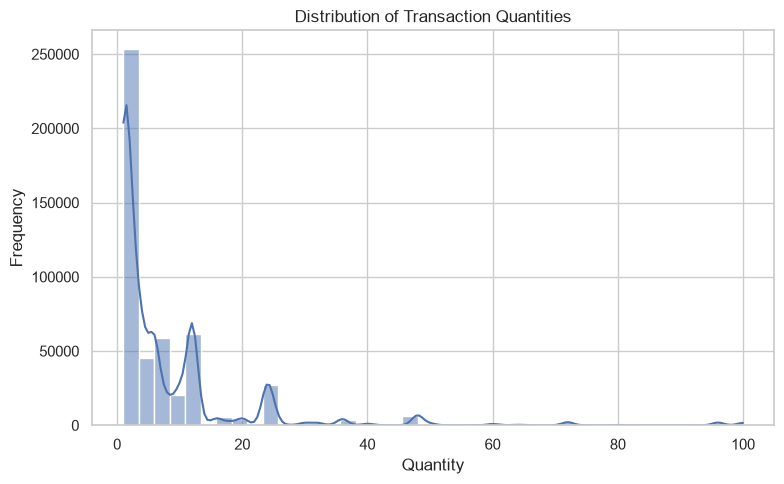

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(
    clean_df.loc[clean_df["Quantity"] <= 100, "Quantity"],
    bins=40,
    kde=True
)

plt.title("Distribution of Transaction Quantities")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

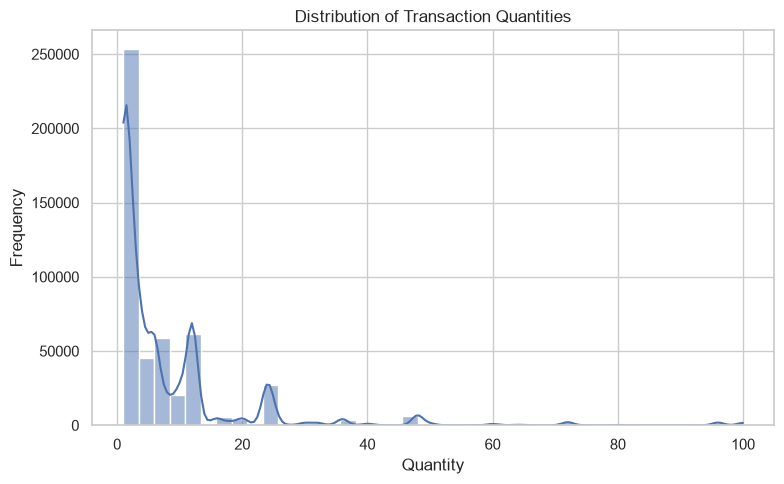

In [33]:
plt.figure(figsize=(8, 5))

sns.histplot(
    clean_df.loc[clean_df["Quantity"] <= 100, "Quantity"],
    bins=40,
    kde=True
)

plt.title("Distribution of Transaction Quantities")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

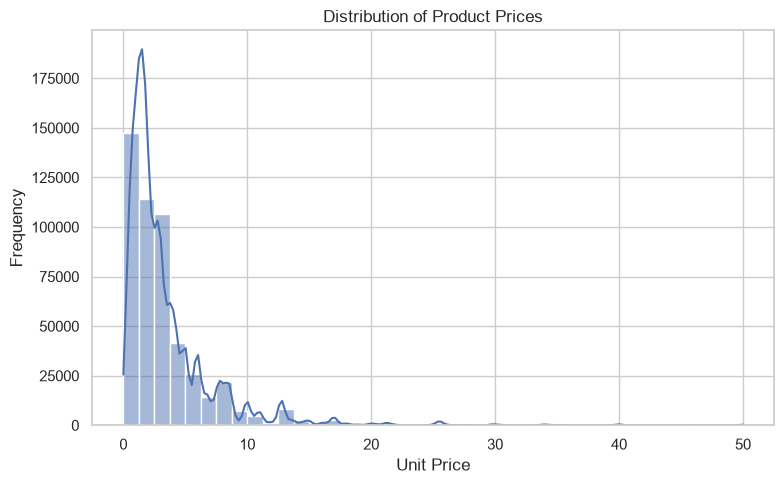

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(
    clean_df.loc[clean_df["Price"] <= 50, "Price"],
    bins=40,
    kde=True
)

plt.title("Distribution of Product Prices")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

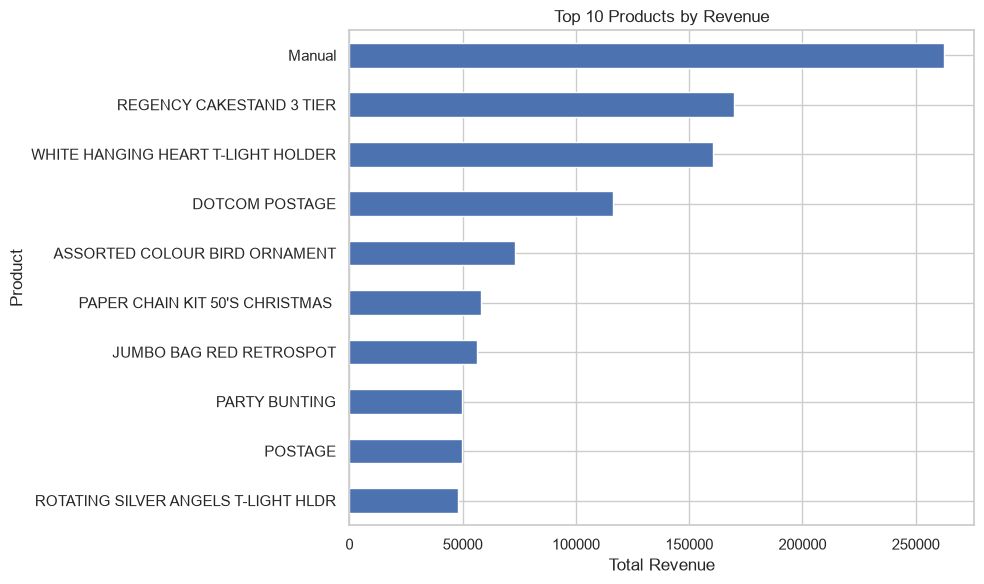

In [35]:
top_products = (
    clean_df.dropna(subset=["Description"])
    .groupby("Description")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

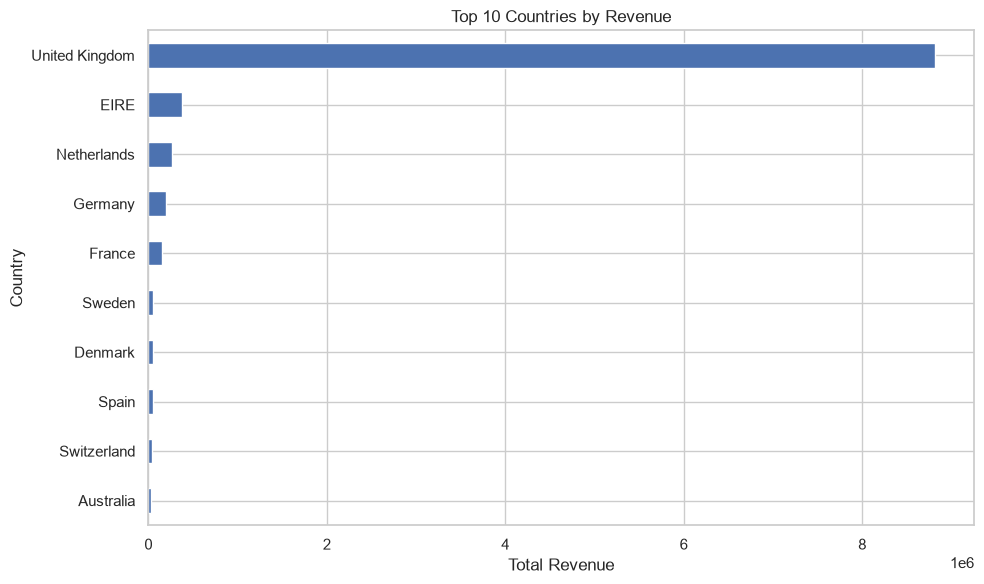

In [36]:
top_countries = (
    clean_df.dropna(subset=["Country"])
    .groupby("Country")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_countries.plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

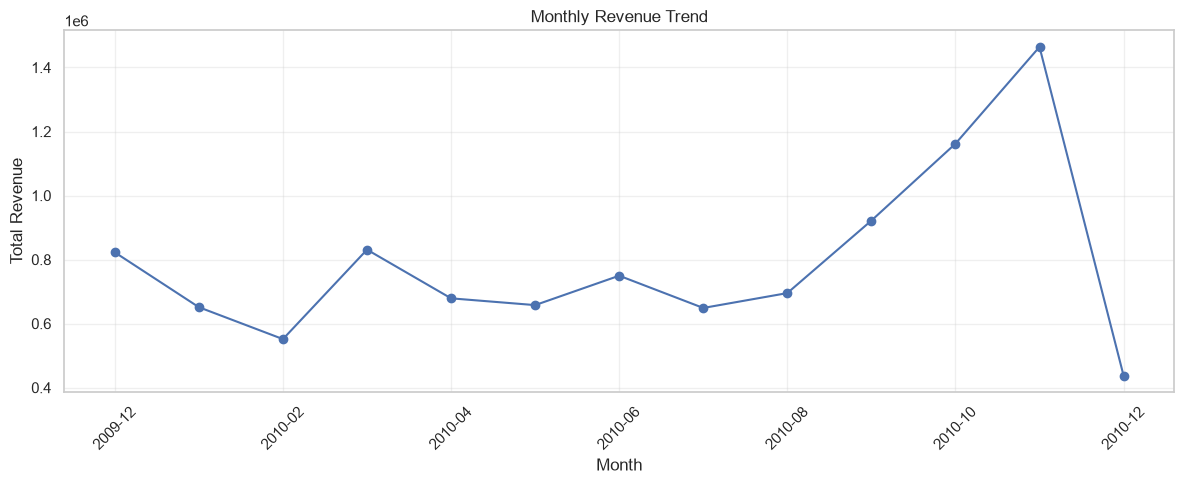

In [37]:
monthly_revenue = (
    clean_df.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

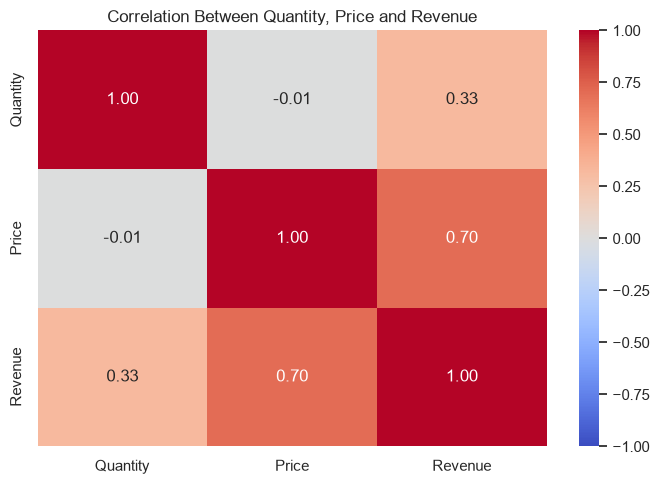

In [38]:
correlation_data = clean_df[
    ["Quantity", "Price", "Revenue"]
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Quantity, Price and Revenue")
plt.tight_layout()
plt.show()

In [39]:
# Aggregate transaction data into daily sales
daily_sales = (
    clean_df
    .set_index("InvoiceDate")
    .resample("D")
    .agg(
        Revenue=("Revenue", "sum"),
        Total_Transactions=("Invoice", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
)

# Fill days without recorded sales with zero
daily_sales[["Revenue", "Total_Transactions", "Total_Quantity"]] = (
    daily_sales[["Revenue", "Total_Transactions", "Total_Quantity"]]
    .fillna(0)
)

daily_sales.index.name = "Date"

print("Daily sales dataset shape:", daily_sales.shape)
display(daily_sales.head(10))

Daily sales dataset shape: (374, 3)


,Revenue,Total_Transactions,Total_Quantity
Date,,,
2009-12-01,54351.23,119,26098
2009-12-02,63172.58,115,31804
2009-12-03,73972.45,124,49221
2009-12-04,40582.32,89,21210
2009-12-05,9803.05,30,5119
2009-12-06,24423.02,74,11533
2009-12-07,44916.21,101,17955
2009-12-08,49476.23,109,23143
2009-12-09,40265.66,88,17840


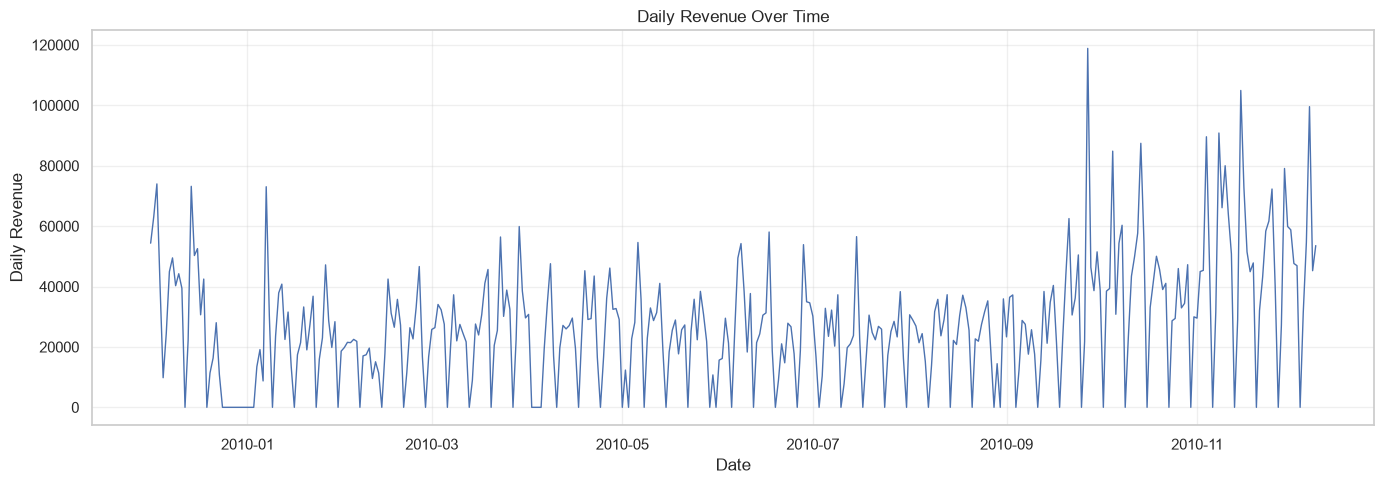

In [40]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales.index,
    daily_sales["Revenue"],
    linewidth=1
)

plt.title("Daily Revenue Over Time")
plt.xlabel("Date")
plt.ylabel("Daily Revenue")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Model Building and Evaluation 

In [42]:
# Copy daily revenue data
model_data = daily_sales[["Revenue"]].copy()

# Calendar features
model_data["DayOfWeek"] = model_data.index.dayofweek
model_data["DayOfMonth"] = model_data.index.day
model_data["Month"] = model_data.index.month
model_data["IsWeekend"] = (model_data.index.dayofweek >= 5).astype(int)

# Historical revenue features
model_data["Lag_1"] = model_data["Revenue"].shift(1)
model_data["Lag_7"] = model_data["Revenue"].shift(7)
model_data["Lag_14"] = model_data["Revenue"].shift(14)

# Rolling averages calculated using previous days only
model_data["RollingMean_7"] = (
    model_data["Revenue"].shift(1).rolling(window=7).mean()
)

model_data["RollingMean_14"] = (
    model_data["Revenue"].shift(1).rolling(window=14).mean()
)

# Remove rows where historical features are unavailable
model_data = model_data.dropna()

print("Model dataset shape:", model_data.shape)
display(model_data.head())

Model dataset shape: (360, 10)


,Revenue,DayOfWeek,DayOfMonth,Month,IsWeekend,Lag_1,Lag_7,Lag_14,RollingMean_7,RollingMean_14
Date,,,,,,,,,,
2009-12-15,50262.29,1,15,12,0,73174.39,49476.23,54351.23,38396.370000,41428.246429
2009-12-16,52545.55,2,16,12,0,50262.29,40265.66,63172.58,38508.664286,41136.179286
2009-12-17,30638.25,3,17,12,0,52545.55,44233.96,73972.45,40262.934286,40377.105714
2009-12-18,42470.29,4,18,12,0,30638.25,39447.89,40582.32,38320.690000,37281.805714
2009-12-19,0.00,5,19,12,1,42470.29,0.00,9803.05,38752.461429,37416.660714


In [43]:
feature_columns = [
    "DayOfWeek",
    "DayOfMonth",
    "Month",
    "IsWeekend",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "RollingMean_7",
    "RollingMean_14"
]

X = model_data[feature_columns]
y = model_data["Revenue"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (360, 9)
Target shape: (360,)


In [44]:
split_index = int(len(model_data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("Training period:",
      model_data.index[0].date(), "to",
      model_data.index[split_index - 1].date())

print("Testing period:",
      model_data.index[split_index].date(), "to",
      model_data.index[-1].date())

Training rows: 288
Testing rows: 72
Training period: 2009-12-15 to 2010-09-28
Testing period: 2010-09-29 to 2010-12-09


In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("MAE")

display(results_df)

,Model,MAE,RMSE,R2
2,Random Forest,13216.637764,18790.061117,0.423814
1,Decision Tree,16396.529710,22971.023702,0.138873
0,Linear Regression,17343.971661,23300.285202,0.114010


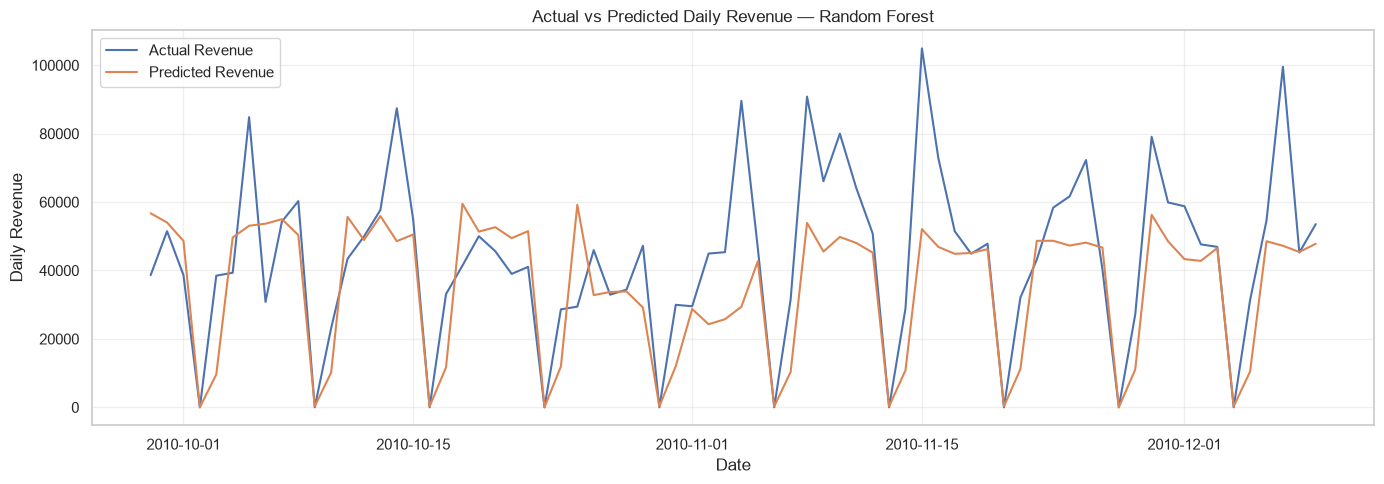

Best model based on test MAE: Random Forest


In [46]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

predictions = best_model.predict(X_test)

plt.figure(figsize=(14, 5))

plt.plot(y_test.index, y_test, label="Actual Revenue")
plt.plot(y_test.index, predictions, label="Predicted Revenue")

plt.title(f"Actual vs Predicted Daily Revenue — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Daily Revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Best model based on test MAE:", best_model_name)

In [47]:
import os
import joblib

# Create a folder for project outputs
os.makedirs("artifacts", exist_ok=True)

# Save model and feature configuration
model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": feature_columns,
    "target": "Revenue",
    "forecast_horizon": "one day ahead",
    "training_data_end": str(X_train.index[-1].date()),
    "test_data_start": str(X_test.index[0].date()),
    "test_data_end": str(X_test.index[-1].date())
}

model_path = "artifacts/online_retail_sales_model.pkl"
joblib.dump(model_bundle, model_path)

print("Model saved successfully:", model_path)
print("Selected model:", best_model_name)

Model saved successfully: artifacts/online_retail_sales_model.pkl
Selected model: Random Forest


In [48]:
daily_sales.to_csv("artifacts/daily_sales_history.csv")

model_data.to_csv("artifacts/modeling_dataset.csv")

print("Daily sales exported to artifacts/daily_sales_history.csv")
print("Model features exported to artifacts/modeling_dataset.csv")

Daily sales exported to artifacts/daily_sales_history.csv
Model features exported to artifacts/modeling_dataset.csv


In [49]:
# Reload the saved model bundle
loaded_bundle = joblib.load(
    "artifacts/online_retail_sales_model.pkl"
)

loaded_model = loaded_bundle["model"]
loaded_features = loaded_bundle["feature_columns"]

# Select one existing test example
sample_X = X_test[loaded_features].iloc[[0]]
actual_revenue = y_test.iloc[0]

# Generate prediction
predicted_revenue = loaded_model.predict(sample_X)[0]

print("Loaded model:", loaded_bundle["model_name"])
print("Date:", sample_X.index[0].date())
print(f"Actual revenue:    {actual_revenue:.2f}")
print(f"Predicted revenue: {predicted_revenue:.2f}")

Loaded model: Random Forest
Date: 2010-09-29
Actual revenue:    38634.22
Predicted revenue: 56709.38


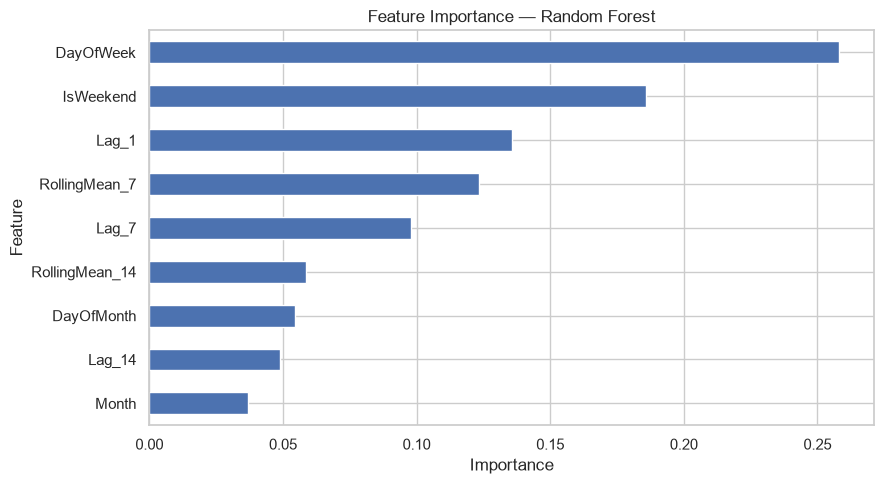

In [50]:
if best_model_name in ["Random Forest", "Decision Tree"]:
    importance = pd.Series(
        best_model.feature_importances_,
        index=feature_columns
    ).sort_values()

    plt.figure(figsize=(9, 5))
    importance.plot(kind="barh")

    plt.title(f"Feature Importance — {best_model_name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print(
        "Feature importance plot skipped: "
        "the selected model is Linear Regression."
    )